# DeepLOB: reproduction and extensions

Zhang, Zohren, Roberts, *DeepLOB: Deep Convolutional Neural Networks for Limit Order Books*, IEEE TSP 67(11), 2019 (arXiv:1808.03668).

Sections 1–6: the code, checked on a small subset (about 12 min on a CPU; these numbers are not results). Section 7: results of the 152 full runs from `results/full_runs.zip`.

Full run of the main recipe (about an hour on an RTX 3090):
`run_experiment(dataset='fi2010', k=10, seed=0, model='deeplob', config='paper', init='keras', zscore=1, out_dir='results_full')`

In [1]:
import os, re, sys, json, glob, time, zipfile, warnings, subprocess
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore', message="Using padding='same'")

if not os.path.exists('data/fi2010_decpre.zip'):          # Colab: get the repository
    if not os.path.exists('deeplob-project'):
        subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/d9nk/deeplob-project.git'], check=True)
    os.chdir('deeplob-project')
if not glob.glob('data/fi2010/Train_Dst_NoAuction_DecPre_CF_7.*'):
    zipfile.ZipFile('data/fi2010_decpre.zip').extractall('data/fi2010')     # 940 MB
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

N_TRAIN = 12_000 if device.type == 'cpu' else 24_000     # subset for Section 6
N_EVAL  = N_TRAIN // 4
EPOCHS  = 2 if device.type == 'cpu' else 5

C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#8a8a8a']
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'axes.axisbelow': True, 'grid.color': '#e1e0d9', 'font.size': 10})
print('device:', device, '| torch', torch.__version__, '| training windows:', N_TRAIN, '| epochs:', EPOCHS)

device: cpu | torch 2.14.0 | training windows: 12000 | epochs: 2


## 1. Task and data

Input: last 100 order book states × 40 features. Target: direction of the mid-price over the next k events (eq. 3 of the paper):

$$m_+(t)=\frac1k\sum_{i=1}^{k}p_{t+i},\qquad l_t=\frac{m_+(t)-p_t}{p_t},\qquad
y_t=\begin{cases}\text{up},& l_t>\alpha\\ \text{down},& l_t<-\alpha\\ \text{stationary},&\text{otherwise}\end{cases}$$

FI-2010: 5 stocks, 10 days. Days 1–7 train (last 20 % validation), days 8–10 test. Label rows: k = 10, 20, 30, 50, 100 (`k=4` in the authors' notebook is the row index, i.e. k = 100).

## 2. Authors' code

From `jupyter_pytorch/run_train_pytorch.ipynb` (github.com/zcakhaa/DeepLOB-Deep-Convolutional-Neural-Networks-for-Limit-Order-Books), copied as is. It differs from the paper:

| | Paper | Authors' notebooks |
|---|---|---|
| Widths | conv 16, Inception 32, ≈60k parameters | conv 32, Inception 64, 143,907 parameters |
| Optimiser | Adam lr 0.01, ε = 1, batch 32 | Adam lr 1e-4, batch 64 (PyTorch) / 128 (TF) |
| Inputs | z-score | DecPre |
| Extras | none mentioned | BatchNorm, Tanh in block 2, dropout (TF), no time padding |
| Horizon | k = 10, 20, 50 | k = 100 only |
| Result | k=10: accuracy 84.47 | k=100: accuracy 73.61 (TF2) / 75.35 (PyTorch) |

In [2]:
def prepare_x(data):
    df1 = data[:40, :].T
    return np.array(df1)

def get_label(data):
    lob = data[-5:, :].T
    return lob

def data_classification(X, Y, T):
    [N, D] = X.shape
    df = np.array(X)

    dY = np.array(Y)

    dataY = dY[T - 1:N]

    dataX = np.zeros((N - T + 1, T, D))
    for i in range(T, N + 1):
        dataX[i - T] = df[i - T:i, :]

    return dataX, dataY

import torch.nn as nn

class deeplob(nn.Module):
    def __init__(self, y_len):
        super().__init__()
        self.y_len = y_len

        # convolution blocks
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=(1,2), stride=(1,2)),
            nn.LeakyReLU(negative_slope=0.01),
#             nn.Tanh(),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(1,2), stride=(1,2)),
            nn.Tanh(),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.Tanh(),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.Tanh(),
            nn.BatchNorm2d(32),
        )
        self.conv3 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(1,10)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
            nn.Conv2d(in_channels=32, out_channels=32, kernel_size=(4,1)),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(32),
        )

        # inception moduels
        self.inp1 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=(1,1), padding='same'),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(64),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=(3,1), padding='same'),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(64),
        )
        self.inp2 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=(1,1), padding='same'),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(64),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=(5,1), padding='same'),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(64),
        )
        self.inp3 = nn.Sequential(
            nn.MaxPool2d((3, 1), stride=(1, 1), padding=(1, 0)),
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=(1,1), padding='same'),
            nn.LeakyReLU(negative_slope=0.01),
            nn.BatchNorm2d(64),
        )

        # lstm layers
        self.lstm = nn.LSTM(input_size=192, hidden_size=64, num_layers=1, batch_first=True)
        self.fc1 = nn.Linear(64, self.y_len)

    def forward(self, x):
        # h0: (number of hidden layers, batch size, hidden size)
        h0 = torch.zeros(1, x.size(0), 64).to(x.device)
        c0 = torch.zeros(1, x.size(0), 64).to(x.device)

        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)

        x_inp1 = self.inp1(x)
        x_inp2 = self.inp2(x)
        x_inp3 = self.inp3(x)

        x = torch.cat((x_inp1, x_inp2, x_inp3), dim=1)

#         x = torch.transpose(x, 1, 2)
        x = x.permute(0, 2, 1, 3)
        x = torch.reshape(x, (-1, x.shape[1], x.shape[2]))

        x, _ = self.lstm(x, (h0, c0))
        x = x[:, -1, :]
        x = self.fc1(x)
        forecast_y = torch.softmax(x, dim=1)

        return forecast_y

print('authors\' model parameters:', sum(p.numel() for p in deeplob(3).parameters()), '(their torchinfo summary: 143,907)')

authors' model parameters: 143907 (their torchinfo summary: 143,907)


## 3. Our implementation

`config='paper'`: widths 16/32/64 (≈60k parameters); `config='code'`: 32/64/64 as in the authors' notebooks; `init='keras'`: Keras default initialisation.

In [3]:
from __future__ import annotations

import os
from dataclasses import dataclass
from typing import Optional

import numpy as np
import torch

FI2010_HORIZON_TO_ROW = {10: 0, 20: 1, 30: 2, 50: 3, 100: 4}   # label rows 144..148
N_FEATURES = 40
CLASS_NAMES = ["up", "stationary", "down"]


def _load_txt_cached(path_txt: str) -> np.ndarray:
    path_npy = path_txt[:-4] + ".npy"
    if os.path.exists(path_npy):
        return np.load(path_npy)
    if not os.path.exists(path_txt):
        raise FileNotFoundError(
            f"{path_txt} not found. DecPre files: unpack data/fi2010_decpre.zip into data/fi2010/; "
            "ZScore / MinMax files come with the full FI-2010 benchmark (etsin.fairdata.fi)."
        )
    arr = np.loadtxt(path_txt, dtype=np.float32)
    np.save(path_npy, arr)
    return arr


FI2010_NORM_FILES = {"decpre": "DecPre", "zscore": "ZScore", "minmax": "MinMax"}


def fi2010_norm_name(norm: str) -> str:
    try:
        return FI2010_NORM_FILES[norm.lower()]
    except KeyError:
        raise ValueError(f"unknown FI-2010 normalisation {norm!r}; choose from {list(FI2010_NORM_FILES.values())}")


def load_fi2010(data_dir: str, norm: str = "DecPre"):
    norm = fi2010_norm_name(norm)
    tr = _load_txt_cached(os.path.join(data_dir, f"Train_Dst_NoAuction_{norm}_CF_7.txt"))
    n_train = int(np.floor(tr.shape[1] * 0.8))   # last 20% of days 1-7 = validation
    train_raw, val_raw = tr[:, :n_train], tr[:, n_train:]
    tests = [
        _load_txt_cached(os.path.join(data_dir, f"Test_Dst_NoAuction_{norm}_CF_{i}.txt"))
        for i in (7, 8, 9)   # days 8, 9, 10
    ]
    test_raw = np.hstack(tests)
    return train_raw, val_raw, test_raw


def load_fi2010_test_prices(data_dir: str) -> np.ndarray:
    return np.hstack([_load_txt_cached(os.path.join(data_dir, f"Test_Dst_NoAuction_DecPre_CF_{i}.txt"))
                      for i in (7, 8, 9)])


def load_fi2010_train_prices(data_dir: str) -> np.ndarray:
    return _load_txt_cached(os.path.join(data_dir, "Train_Dst_NoAuction_DecPre_CF_7.txt"))


def fi2010_loso_split(train_file_raw: np.ndarray, test_raw: np.ndarray, holdout: int,
                      train_prices: np.ndarray, test_prices: np.ndarray, val_frac: float = 0.2, n_stocks: int = 5):
    b_tr = fi2010_segment_boundaries(train_prices); b_te = fi2010_segment_boundaries(test_prices)
    if len(b_tr) + 1 != n_stocks or (len(b_te) + 1) % n_stocks:
        raise ValueError(f"unexpected FI-2010 segment structure: {len(b_tr)+1} train segments, {len(b_te)+1} test segments")
    seg_tr = np.split(np.arange(train_file_raw.shape[1]), b_tr)
    seg_te = np.split(np.arange(test_raw.shape[1]), b_te)
    out = {}
    for name, sel in (("train", 0), ("val", 1)):
        parts, starts, n = [], [], 0
        for i, cols in enumerate(seg_tr):
            if i == holdout:
                continue
            cut = int(len(cols) * (1 - val_frac))
            c = cols[:cut] if sel == 0 else cols[cut:]
            starts.append(n); parts.append(train_file_raw[:, c]); n += len(c)
        out[name] = (np.hstack(parts), np.array(starts[1:], dtype=int))
    parts, starts, prices, n = [], [], [], 0
    for j, cols in enumerate(seg_te):
        if j % n_stocks == holdout:
            starts.append(n); parts.append(test_raw[:, cols]); prices.append(test_prices[:, cols]); n += len(cols)
    out["test"] = (np.hstack(parts), np.array(starts[1:], dtype=int), np.hstack(prices))
    return out


def fi2010_zscore_per_stock(train_file_raw: np.ndarray, test_raw: np.ndarray, train_prices: np.ndarray,
                            test_prices: np.ndarray, n_stocks: int = 5):
    b_tr = fi2010_segment_boundaries(train_prices); b_te = fi2010_segment_boundaries(test_prices)
    seg_tr = np.split(np.arange(train_file_raw.shape[1]), b_tr); seg_te = np.split(np.arange(test_raw.shape[1]), b_te)
    trz, tez = train_file_raw.copy(), test_raw.copy()
    for s_ in range(n_stocks):
        ref = train_file_raw[:N_FEATURES, seg_tr[s_]]
        mu, sd = ref.mean(1, keepdims=True), ref.std(1, keepdims=True) + 1e-8
        trz[:N_FEATURES, seg_tr[s_]] = (ref - mu) / sd
        for j, cols in enumerate(seg_te):
            if j % n_stocks == s_:
                tez[:N_FEATURES, cols] = (test_raw[:N_FEATURES, cols] - mu) / sd
    return trz, tez


def fi2010_xy(raw: np.ndarray, k: int):
    row = FI2010_HORIZON_TO_ROW[k]
    X = np.ascontiguousarray(raw[:N_FEATURES].T, dtype=np.float32)
    y = (raw[144 + row] - 1).astype(np.int64)   # 1,2,3 -> 0 up, 1 stationary, 2 down
    return X, y


def fi2010_mid_bid_ask(raw: np.ndarray):
    ask, bid = raw[0], raw[2]   # best ask / best bid price
    return (ask + bid) / 2.0, bid, ask


def fi2010_segment_boundaries(raw: np.ndarray, jump: float = 0.05):
    mid, _, _ = fi2010_mid_bid_ask(raw)
    rel = np.abs(np.diff(mid)) / mid[:-1]
    return np.where(rel > jump)[0] + 1   # price jump = next stock


@dataclass
class WindowData:
    X: torch.Tensor
    y: torch.Tensor
    T: int
    valid_starts: torch.Tensor

    def __len__(self):
        return int(self.valid_starts.numel())

    @property
    def device(self):
        return self.X.device

    def labels(self) -> torch.Tensor:
        return self.y[self.valid_starts + self.T - 1]

    def batch(self, starts: torch.Tensor):
        ar = torch.arange(self.T, device=self.X.device)
        idx = starts[:, None] + ar[None, :]
        return self.X[idx], self.y[starts + self.T - 1]

    def iterate(self, batch_size: int, shuffle: bool, generator: Optional[torch.Generator] = None):
        n = len(self)
        if shuffle:
            perm = torch.randperm(n, generator=generator, device="cpu").to(self.X.device)
        else:
            perm = torch.arange(n, device=self.X.device)
        for s in range(0, n, batch_size):
            starts = self.valid_starts[perm[s : s + batch_size]]
            yield self.batch(starts)


def make_window_data(
    X: np.ndarray,
    y: np.ndarray,
    T: int,
    device,
    segment_starts: Optional[np.ndarray] = None,
    label_valid: Optional[np.ndarray] = None,
    max_samples: Optional[int] = None,
) -> WindowData:
    N = X.shape[0]
    valid = np.ones(N - T + 1, dtype=bool)
    if segment_starts is not None:
        bounds = np.concatenate([[0], np.asarray(segment_starts), [N]])
        valid[:] = False
        for a, b in zip(bounds[:-1], bounds[1:]):
            if b - a >= T:
                valid[a : b - T + 1] = True
    if label_valid is not None:
        valid &= label_valid[T - 1 : N]
    starts = np.where(valid)[0]
    if max_samples is not None:
        starts = starts[:max_samples]
    return WindowData(
        X=torch.from_numpy(X).to(device),
        y=torch.from_numpy(y).to(device),
        T=T,
        valid_starts=torch.from_numpy(starts).to(device),
    )


def apply_embargo(y_valid: np.ndarray, k: int, split_end: int) -> np.ndarray:
    y_valid = y_valid.copy()
    y_valid[max(0, split_end - k) : split_end] = False
    return y_valid


def smoothed_label_signal(mid: np.ndarray, k: int, method: str = "eq4") -> np.ndarray:
    mid = mid.astype(np.float64)
    N = len(mid)
    cs = np.concatenate([[0.0], np.cumsum(mid)])
    t = np.arange(N)
    fut_end = t + 1 + k
    m_plus = np.full(N, np.nan)
    ok = fut_end <= N
    m_plus[ok] = (cs[fut_end[ok]] - cs[t[ok] + 1]) / k   # mean of the next k mid-prices
    if method == "eq3":   # eq. 3 of the paper, otherwise eq. 4
        return (m_plus - mid) / mid
    past_start = np.maximum(t + 1 - k, 0)
    m_minus = (cs[t + 1] - cs[past_start]) / (t + 1 - past_start)
    return (m_plus - m_minus) / m_minus


def signal_to_label(l: np.ndarray, alpha: float) -> np.ndarray:
    lab = np.ones(len(l), dtype=np.int64)
    lab[l > alpha] = 0
    lab[l < -alpha] = 2
    return lab


In [4]:
from __future__ import annotations

import numpy as np
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_recall_fscore_support)


def classification_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    out = {"accuracy": float(accuracy_score(y_true, y_pred))}
    for avg in ("macro", "weighted"):
        p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average=avg, zero_division=0)
        out[f"precision_{avg}"] = float(p)
        out[f"recall_{avg}"] = float(r)
        out[f"f1_{avg}"] = float(f)
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], zero_division=0)
    out["per_class"] = {
        "precision": p.tolist(), "recall": r.tolist(), "f1": f.tolist(), "support": s.tolist()}
    out["confusion_matrix"] = confusion_matrix(y_true, y_pred, labels=[0, 1, 2]).tolist()
    out["class_share_true"] = (np.bincount(y_true, minlength=3) / len(y_true)).tolist()
    out["class_share_pred"] = (np.bincount(y_pred, minlength=3) / len(y_pred)).tolist()
    return out


def majority_baseline(y_train: np.ndarray, y_test: np.ndarray) -> dict:
    maj = int(np.bincount(y_train, minlength=3).argmax())
    return classification_metrics(y_test, np.full_like(y_test, maj))


In [5]:
from __future__ import annotations

import torch
import torch.nn as nn

CONFIGS = {
    "paper": dict(n_filters=16, incep=32, lstm=64, dropout=0.0),
    "code": dict(n_filters=32, incep=64, lstm=64, dropout=0.2),
}


def _conv_block_time(ch: int, act):
    return nn.Sequential(
        nn.Conv2d(ch, ch, kernel_size=(4, 1), padding="same"), act(),
        nn.Conv2d(ch, ch, kernel_size=(4, 1), padding="same"), act(),
    )


class ConvStack(nn.Module):
    def __init__(self, n_filters: int):
        super().__init__()
        act = lambda: nn.LeakyReLU(negative_slope=0.01)
        F_ = n_filters
        self.block1 = nn.Sequential(
            nn.Conv2d(1, F_, kernel_size=(1, 2), stride=(1, 2)), act(), _conv_block_time(F_, act))    # price + volume
        self.block2 = nn.Sequential(
            nn.Conv2d(F_, F_, kernel_size=(1, 2), stride=(1, 2)), act(), _conv_block_time(F_, act))   # ask + bid
        self.block3 = nn.Sequential(
            nn.Conv2d(F_, F_, kernel_size=(1, 10)), act(), _conv_block_time(F_, act))                 # 10 levels

    def forward(self, x):
        return self.block3(self.block2(self.block1(x)))


class Inception(nn.Module):
    def __init__(self, in_ch: int, ch: int):
        super().__init__()
        act = lambda: nn.LeakyReLU(negative_slope=0.01)
        self.b1 = nn.Sequential(
            nn.Conv2d(in_ch, ch, (1, 1)), act(), nn.Conv2d(ch, ch, (3, 1), padding="same"), act())
        self.b2 = nn.Sequential(
            nn.Conv2d(in_ch, ch, (1, 1)), act(), nn.Conv2d(ch, ch, (5, 1), padding="same"), act())
        self.b3 = nn.Sequential(
            nn.MaxPool2d((3, 1), stride=(1, 1), padding=(1, 0)), nn.Conv2d(in_ch, ch, (1, 1)), act())
        self.out_channels = 3 * ch

    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x)], dim=1)


class DeepLOB(nn.Module):
    def __init__(self, n_filters=16, incep=32, lstm=64, dropout=0.0, n_classes=3, T=100,
                 use_inception=True, head="lstm"):
        super().__init__()
        self.conv = ConvStack(n_filters)
        self.use_inception = use_inception
        if use_inception:
            self.incep = Inception(n_filters, incep)
            feat = self.incep.out_channels
        else:
            feat = n_filters
        self.drop = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
        self.head_type = head
        if head == "lstm":
            self.lstm = nn.LSTM(input_size=feat, hidden_size=lstm, batch_first=True)
            self.fc = nn.Linear(lstm, n_classes)
        elif head == "dense":
            self.fc = nn.Sequential(nn.Flatten(), nn.Linear(T * feat, 64),
                                    nn.LeakyReLU(0.01), nn.Linear(64, n_classes))
        else:
            raise ValueError(head)

    def features(self, x):
        x = x.unsqueeze(1)
        x = self.conv(x)
        if self.use_inception:
            x = self.incep(x)
        x = x.squeeze(-1).permute(0, 2, 1)   # (batch, T, channels)
        return self.drop(x)

    def forward(self, x):
        h = self.features(x)
        if self.head_type == "lstm":
            out, _ = self.lstm(h)
            return self.fc(out[:, -1, :])
        return self.fc(h)


class LSTMOnly(nn.Module):
    def __init__(self, lstm=64, n_classes=3):
        super().__init__()
        self.lstm = nn.LSTM(40, lstm, batch_first=True)
        self.fc = nn.Linear(lstm, n_classes)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])


class LinearLast(nn.Module):
    def __init__(self, n_classes=3):
        super().__init__()
        self.fc = nn.Linear(40, n_classes)

    def forward(self, x):
        return self.fc(x[:, -1, :])


class LinearWindow(nn.Module):
    def __init__(self, T=100, n_classes=3):
        super().__init__()
        self.fc = nn.Linear(T * 40, n_classes)

    def forward(self, x):
        return self.fc(x.flatten(1))


class DeepLOBAuthors(deeplob):   # the authors' class of Section 2 on our (B, T, 40) batches
    def __init__(self):
        super().__init__(y_len=3)

    def forward(self, x):
        return super().forward(x.unsqueeze(1) if x.dim() == 3 else x)


MODEL_NAMES = ["deeplob", "deeplob_authors", "deeplob_noincep", "deeplob_nolstm", "lstm_only",
               "linear_last", "linear_window"]


INIT_NAMES = ["torch", "keras"]


def keras_init_(module: nn.Module) -> nn.Module:   # Keras defaults: glorot, orthogonal, forget bias 1
    for m in module.modules():
        if isinstance(m, (nn.Conv2d, nn.Linear)):
            nn.init.xavier_uniform_(m.weight)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LSTM):
            H = m.hidden_size
            for pname, prm in m.named_parameters():
                if "weight_ih" in pname:
                    nn.init.xavier_uniform_(prm)
                elif "weight_hh" in pname:
                    nn.init.orthogonal_(prm)
                elif "bias" in pname:
                    nn.init.zeros_(prm)
                    if "bias_ih" in pname:
                        with torch.no_grad():
                            prm[H:2 * H].fill_(1.0)
    return module


def build_model(name: str, config: str = "paper", T: int = 100, init: str = "torch") -> nn.Module:
    cfg = CONFIGS[config]
    if name == "deeplob":
        m = DeepLOB(**cfg, T=T)
    elif name == "deeplob_authors":
        m = DeepLOBAuthors()
    elif name == "deeplob_noincep":
        m = DeepLOB(**cfg, T=T, use_inception=False)
    elif name == "deeplob_nolstm":
        m = DeepLOB(**cfg, T=T, head="dense")
    elif name == "lstm_only":
        m = LSTMOnly(lstm=cfg["lstm"])
    elif name == "linear_last":
        m = LinearLast()
    elif name == "linear_window":
        m = LinearWindow(T=T)
    else:
        raise ValueError(f"unknown model {name}; choose from {MODEL_NAMES}")
    if init == "keras" and name != "deeplob_authors":
        keras_init_(m)
    elif init not in INIT_NAMES:
        raise ValueError(f"unknown init {init}; choose from {INIT_NAMES}")
    return m


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


In [6]:
from __future__ import annotations

import copy
import os
import random
import time

import numpy as np
import torch
import torch.nn as nn



def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def predict(model: nn.Module, data: WindowData, batch_size: int = 1024):
    model.eval()
    logits, ys = [], []
    for xb, yb in data.iterate(batch_size, shuffle=False):
        logits.append(model(xb).float().cpu())
        ys.append(yb.cpu())
    return torch.cat(logits).numpy(), torch.cat(ys).numpy()


@torch.no_grad()
def evaluate(model: nn.Module, data: WindowData, criterion, batch_size: int = 1024):
    logits, y = predict(model, data, batch_size)
    loss = float(criterion(torch.from_numpy(logits), torch.from_numpy(y)))
    m = classification_metrics(y, logits.argmax(1))
    m["loss"] = loss
    return m, logits, y


def _save_checkpoint(path: str, state: dict):
    tmp = path + ".tmp"
    torch.save(state, tmp)
    os.replace(tmp, path)


def train_model(
    model: nn.Module,
    train: WindowData,
    val: WindowData,
    *,
    epochs: int,
    patience: int,
    batch_size: int,
    lr: float,
    adam_eps: float,
    es_metric: str = "loss",
    seed: int = 0,
    log=print,
    max_minutes: float | None = None,
    ckpt_path: str | None = None,
):
    criterion = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr, eps=adam_eps)
    gen = torch.Generator(device="cpu").manual_seed(seed)

    best_score, best_state, best_epoch, bad = -np.inf, copy.deepcopy(model.state_dict()), -1, 0
    history, start_epoch, elapsed_before = [], 0, 0.0

    if ckpt_path and os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=train.device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["optimizer"])
        best_score, best_state, best_epoch, bad = ck["best_score"], ck["best_state"], ck["best_epoch"], ck["bad"]
        history, start_epoch, elapsed_before = ck["history"], ck["epoch"] + 1, ck["elapsed_seconds"]
        gen.set_state(ck["gen_state"].cpu()); torch.set_rng_state(ck["torch_rng"].cpu())
        if torch.cuda.is_available() and ck.get("cuda_rng") is not None:
            torch.cuda.set_rng_state_all([st.cpu() for st in ck["cuda_rng"]])
        log(f"resumed from checkpoint: {start_epoch} epochs done, best epoch {best_epoch+1}, "
            f"{elapsed_before/60:.1f} min already spent")

    t_start = time.time() - elapsed_before
    stopped = start_epoch >= epochs
    for ep in range(start_epoch, epochs):
        model.train()
        t0 = time.time()
        tot, n = torch.zeros((), device=train.device), 0
        for xb, yb in train.iterate(batch_size, shuffle=True, generator=gen):
            opt.zero_grad(set_to_none=True)
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
            tot += loss.detach() * len(yb)
            n += len(yb)
        train_loss = tot.item() / max(n, 1)
        vm, _, _ = evaluate(model, val, criterion)
        score = -vm["loss"] if es_metric == "loss" else vm["accuracy"]
        improved = score > best_score
        if improved:
            best_score, best_epoch, bad = score, ep, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
        dt = time.time() - t0
        history.append(dict(epoch=ep, train_loss=train_loss, val_loss=vm["loss"],
                            val_acc=vm["accuracy"], val_f1_macro=vm["f1_macro"], seconds=dt))
        log(f"epoch {ep+1:3d}/{epochs} train_loss {train_loss:.4f} val_loss {vm['loss']:.4f} "
            f"val_acc {vm['accuracy']:.4f} val_f1m {vm['f1_macro']:.4f} "
            f"{dt:.0f}s {'*' if improved else ''}")
        if ckpt_path:
            _save_checkpoint(ckpt_path, dict(
                model=model.state_dict(), optimizer=opt.state_dict(), epoch=ep, history=history,
                best_score=best_score, best_state=best_state, best_epoch=best_epoch, bad=bad,
                elapsed_seconds=time.time() - t_start, gen_state=gen.get_state(),
                torch_rng=torch.get_rng_state(),
                cuda_rng=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None))
        if bad >= patience:
            log(f"early stopping: no improvement in {patience} epochs (best epoch {best_epoch+1})")
            break
        if max_minutes is not None and (time.time() - t_start) / 60 > max_minutes:
            log(f"time budget of {max_minutes} min reached, stopping")
            break
    if stopped:
        log("checkpoint already contains all epochs; evaluating the best state")
    model.load_state_dict(best_state)   # best validation epoch
    return model, dict(history=history, best_epoch=best_epoch + 1,
                       total_minutes=(time.time() - t_start) / 60)


In [7]:
from __future__ import annotations

import glob
import os
import re

import numpy as np
import pandas as pd


TARDIS_COLS = [f"{side}[{i}].{f}" for i in range(10) for side, f in
               (("asks", "price"), ("asks", "amount"), ("bids", "price"), ("bids", "amount"))]


def parse_tardis_day(path: str, stride: int = 10):
    df = pd.read_csv(path, usecols=["timestamp"] + TARDIS_COLS)
    df = df.iloc[::stride]   # every 10th snapshot
    X = df[TARDIS_COLS].to_numpy(dtype=np.float64)
    ts = df["timestamp"].to_numpy(dtype=np.int64)
    mid = (X[:, 0] + X[:, 2]) / 2.0
    return X, mid, ts


def build_symbol_npz(raw_dir: str, symbol: str, out_path: str, stride: int = 10, log=print):
    files = sorted(glob.glob(os.path.join(raw_dir, f"*_{symbol}.csv.gz")))
    if not files:
        raise FileNotFoundError(f"no raw files for {symbol} in {raw_dir}")
    Xs, mids, tss, day_ids, dates = [], [], [], [], []
    for d, f in enumerate(files):
        date = re.search(r"(\d{4}-\d{2}-\d{2})", os.path.basename(f)).group(1)
        X, mid, ts = parse_tardis_day(f, stride)
        log(f"  {symbol} {date}: {len(X):,} snapshots after stride={stride}")
        Xs.append(X); mids.append(mid); tss.append(ts)
        day_ids.append(np.full(len(X), d, dtype=np.int32)); dates.append(date)
    np.savez_compressed(out_path, X_raw=np.concatenate(Xs), mid=np.concatenate(mids),
                        ts=np.concatenate(tss), day_id=np.concatenate(day_ids),
                        dates=np.array(dates), stride=stride)
    log(f"saved {out_path}")


def zscore_by_previous_days(X_raw: np.ndarray, day_id: np.ndarray, norm_days: int = 5):
    X = np.empty_like(X_raw, dtype=np.float32)
    days = np.unique(day_id)
    for d in days:
        prev = [p for p in days if d - norm_days <= p < d]   # statistics of the previous 5 days
        ref = X_raw[np.isin(day_id, prev)] if prev else X_raw[day_id == d]
        mu, sd = ref.mean(0), ref.std(0) + 1e-12
        X[day_id == d] = ((X_raw[day_id == d] - mu) / sd).astype(np.float32)
    return X


def load_crypto(npz_path: str, k: int, *, train_days, val_days, test_days, alpha="auto",
                label_method: str = "eq4", stat_share: float = 1 / 3, norm_days: int = 5,
                log=print):
    z = np.load(npz_path, allow_pickle=True)
    X_raw, mid, day_id = z["X_raw"], z["mid"], z["day_id"]
    dates = [str(d) for d in z["dates"]]
    X = zscore_by_previous_days(X_raw, day_id, norm_days)

    l = np.full(len(mid), np.nan)
    for d in np.unique(day_id):
        m = day_id == d
        l[m] = smoothed_label_signal(mid[m], k, label_method)

    if alpha == "auto":
        tr_mask = np.isin(day_id, train_days) & ~np.isnan(l)
        alpha = float(np.quantile(np.abs(l[tr_mask]), stat_share))   # 1/3 of the train labels = stationary
    y = signal_to_label(l, alpha)
    label_valid = ~np.isnan(l)

    out = {"alpha": alpha, "dates": dates, "k": k, "label_method": label_method}
    for name, days in (("train", train_days), ("val", val_days), ("test", test_days)):
        m = np.isin(day_id, days)
        idx = np.where(m)[0]
        dsub = day_id[idx]
        seg = np.where(np.diff(dsub) != 0)[0] + 1
        share = np.bincount(y[idx][label_valid[idx]], minlength=3) / max(label_valid[idx].sum(), 1)
        out[name] = dict(X=np.ascontiguousarray(X[idx]), y=y[idx], label_valid=label_valid[idx],
                         segment_starts=seg, class_share=share.tolist(),
                         dates=[dates[d] for d in days], mid=mid[idx], X_raw=X_raw[idx])
        log(f"  {name}: days {[dates[d] for d in days]} n={len(idx):,} "
            f"class share up/stat/down = {np.round(share, 3).tolist()}")
    log(f"  alpha = {alpha:.3e} ({label_method}, k={k})")
    return out


In [8]:
from __future__ import annotations

import numpy as np


def _run_side(sig, mid, bid, ask, seg_bounds, side, delay, cost, fee_bps):
    trades = []
    for s, (a, b) in enumerate(zip(seg_bounds[:-1], seg_bounds[1:])):
        pos_open, entry = False, 0.0
        t = a
        while t < b:
            exec_t = min(t + delay, b - 1)   # trade `delay` events after the signal
            if not pos_open and sig[t] == side:
                if cost == "mid":
                    entry = mid[exec_t]
                else:
                    entry = ask[exec_t] if side == 1 else bid[exec_t]
                pos_open, entry_mid = True, mid[exec_t]
                t = exec_t + 1
                continue
            if pos_open and sig[t] == -side:
                if cost == "mid":
                    px = mid[exec_t]
                else:
                    px = bid[exec_t] if side == 1 else ask[exec_t]
                pnl = side * (px - entry) / entry_mid * 1e4 - 2 * fee_bps   # bps, fee on both legs
                trades.append((s, pnl))
                pos_open = False
                t = exec_t + 1
                continue
            t += 1
        if pos_open:
            px = mid[b - 1] if cost == "mid" else (bid[b - 1] if side == 1 else ask[b - 1])
            trades.append((s, side * (px - entry) / entry_mid * 1e4 - 2 * fee_bps))
    return trades


def simulate(pred: np.ndarray, mid: np.ndarray, bid: np.ndarray, ask: np.ndarray,
             segment_starts=None, delay: int = 5, cost: str = "mid", fee_bps: float = 0.0):
    sig = np.where(pred == 0, 1, np.where(pred == 2, -1, 0))   # +1 up, -1 down
    N = len(sig)
    seg = np.concatenate([[0], np.asarray(segment_starts if segment_starts is not None else []),
                          [N]]).astype(int)
    trades = _run_side(sig, mid, bid, ask, seg, +1, delay, cost, fee_bps) + \
             _run_side(sig, mid, bid, ask, seg, -1, delay, cost, fee_bps)
    if not trades:
        return dict(n_trades=0, total_pnl_bps=0.0, mean_pnl_bps=0.0, median_pnl_bps=0.0, win_rate=0.0,
                    tstat_segments=float("nan"), n_segments=len(seg) - 1,
                    avg_spread_bps=float(np.mean((ask - bid) / mid) * 1e4), cost=cost, fee_bps=fee_bps)
    seg_id = np.array([t[0] for t in trades]); pnl = np.array([t[1] for t in trades])
    per_seg = np.array([pnl[seg_id == s].sum() for s in np.unique(seg_id)])
    tstat = per_seg.mean() / (per_seg.std(ddof=1) / np.sqrt(len(per_seg))) if len(per_seg) > 1 else float("nan")
    spread_bps = float(np.mean((ask - bid) / mid) * 1e4)
    return dict(n_trades=int(len(pnl)), total_pnl_bps=float(pnl.sum()),
                mean_pnl_bps=float(pnl.mean()), median_pnl_bps=float(np.median(pnl)),
                win_rate=float((pnl > 0).mean()), tstat_segments=float(tstat),
                n_segments=int(len(per_seg)), avg_spread_bps=spread_bps, cost=cost, fee_bps=fee_bps)


In [9]:
from __future__ import annotations

import json
import os
import time

import numpy as np
import torch


TRAIN_DEFAULTS = {
    "paper": dict(lr=0.01, adam_eps=1.0, batch_size=32, epochs=100, patience=20, es_metric="acc"),   # Section IV-C
    "code": dict(lr=1e-4, adam_eps=1e-8, batch_size=64, epochs=50, patience=50, es_metric="loss"),   # authors' notebook
}

DEFAULTS = dict(
    dataset="fi2010", data_dir="data/fi2010", norm="DecPre", k=10, T=100, seed=0,
    model="deeplob", config="paper", init="torch", zscore=0,
    lr=None, adam_eps=None, batch_size=None, epochs=None, patience=None, es_metric=None,
    max_minutes=None,
    embargo=0, mask_stock_boundaries=0, holdout_stock=None,
    npz="data/crypto/BTCUSDT_stride10.npz", train_days="1-8", val_days="9,10", test_days="11,12",
    alpha="auto", label_method="eq4", stat_share=1 / 3, transfer_npz=None, transfer_test_days="1,2",
    max_train_samples=None, max_val_samples=None, max_test_samples=None,
    out_dir="results", tag="", device="cuda" if torch.cuda.is_available() else "cpu",
    overwrite=False,
)


def parse_days(s: str):
    out = []
    for part in str(s).split(","):
        if "-" in part:
            a, b = part.split("-"); out += list(range(int(a), int(b) + 1))
        elif part.strip():
            out.append(int(part))
    return out


def run_name_of(a: dict) -> str:
    norm = a.get("norm", "DecPre") if a.get("dataset", "fi2010") == "fi2010" else "DecPre"
    return f"{a['dataset']}_k{a['k']}_{a['model']}_{a['config']}_s{a['seed']}" + \
           (f"_{norm.lower()}" if norm.lower() != "decpre" else "") + \
           ("_kinit" if a.get("init", "torch") == "keras" else "") + \
           ({0: "", 1: "_zs", 2: "_zsps"}.get(int(a.get("zscore") or 0), "_zs")) + \
           (f"_loso{a['holdout_stock']}" if a.get("holdout_stock") is not None else "") + \
           (f"_{a['tag']}" if a.get("tag") else "")


def run_experiment(**kwargs) -> dict:
    a = dict(DEFAULTS); a.update(kwargs)
    hp = dict(TRAIN_DEFAULTS[a["config"]])
    for key in hp:
        if a.get(key) is not None:
            hp[key] = a[key]

    run_name = run_name_of(a)
    out = os.path.join(a["out_dir"], run_name)
    os.makedirs(out, exist_ok=True)
    result_path = os.path.join(out, "result.json")
    ckpt_path = os.path.join(out, "checkpoint.pt")
    if os.path.exists(result_path) and not a.get("overwrite"):
        print(f"skip {run_name}: result.json exists (pass overwrite=True to redo)", flush=True)
        return json.load(open(result_path))
    resuming = os.path.exists(ckpt_path)
    logf = open(os.path.join(out, "log.txt"), "a" if resuming else "w")

    def log(msg, stdout=True):
        if stdout:
            print(msg, flush=True)
        logf.write(msg + "\n"); logf.flush()

    log(f"run {run_name}   hyper-parameters {hp}" + ("   [RESUMING]" if resuming else ""))
    log(f"args {a}", stdout=False)
    set_seed(a["seed"])
    torch.backends.cudnn.benchmark = True
    device = torch.device(a["device"])
    t0 = time.time()

    extra = {}
    if a["dataset"] == "fi2010":
        train_raw, val_raw, test_raw = load_fi2010(a["data_dir"], a["norm"])
        if int(a["zscore"] or 0) == 2:
            decpre = a["norm"].lower() == "decpre"
            n_tr = train_raw.shape[1]
            trf, test_raw = fi2010_zscore_per_stock(
                np.hstack([train_raw, val_raw]), test_raw,
                np.hstack([train_raw, val_raw]) if decpre else load_fi2010_train_prices(a["data_dir"]),
                test_raw if decpre else load_fi2010_test_prices(a["data_dir"]))
            train_raw, val_raw = trf[:, :n_tr], trf[:, n_tr:]
            log("features standardised per stock with that stock's train-period statistics (z-score 2)")
        loso = None
        if a["holdout_stock"] is not None:
            loso = fi2010_loso_split(np.hstack([train_raw, val_raw]), test_raw, int(a["holdout_stock"]),
                                     load_fi2010_train_prices(a["data_dir"]), load_fi2010_test_prices(a["data_dir"]))
            train_raw, val_raw, test_raw = loso["train"][0], loso["val"][0], loso["test"][0]
            log(f"leave-one-stock-out: held-out stock {a['holdout_stock']}; train cols {train_raw.shape[1]:,} "
                f"val {val_raw.shape[1]:,} test {test_raw.shape[1]:,} (3 test days of that stock)")
        Xtr, ytr = fi2010_xy(train_raw, a["k"])
        Xva, yva = fi2010_xy(val_raw, a["k"])
        Xte, yte = fi2010_xy(test_raw, a["k"])
        if int(a["zscore"] or 0) == 1:
            mu, sd = Xtr.mean(0, keepdims=True), Xtr.std(0, keepdims=True) + 1e-8
            Xtr, Xva, Xte = ((Xtr - mu) / sd).astype(np.float32), ((Xva - mu) / sd).astype(np.float32), ((Xte - mu) / sd).astype(np.float32)
            log("features standardised with train-split statistics (z-score)")
        lv_tr = np.ones(len(ytr), bool)
        if a["embargo"]:
            lv_tr = apply_embargo(lv_tr, a["k"], len(ytr))
        if loso is not None:
            price_raw = loso["test"][2]
            seg_tr, seg_va, seg_te = loso["train"][1], loso["val"][1], loso["test"][1]
        else:
            raw_prices = a["norm"].lower() == "decpre" and int(a["zscore"] or 0) != 2
            price_raw = test_raw if raw_prices else load_fi2010_test_prices(a["data_dir"])
            if a["mask_stock_boundaries"]:
                trp = np.hstack([train_raw, val_raw]) if raw_prices else load_fi2010_train_prices(a["data_dir"])
                b = fi2010_segment_boundaries(trp); n_tr = train_raw.shape[1]
                seg_tr, seg_va = b[b < n_tr], b[b >= n_tr] - n_tr
            else:
                seg_tr = seg_va = None
            seg_te = fi2010_segment_boundaries(price_raw)
        train = make_window_data(Xtr, ytr, a["T"], device, seg_tr, lv_tr, a["max_train_samples"])
        val = make_window_data(Xva, yva, a["T"], device, seg_va, None, a["max_val_samples"])
        test = make_window_data(Xte, yte, a["T"], device, seg_te if (a["mask_stock_boundaries"] or loso is not None) else None,
                                None, a["max_test_samples"])
        mid, bid, ask = fi2010_mid_bid_ask(price_raw)
        extra.update(test_mid=mid, test_bid=bid, test_ask=ask, test_segment_starts=seg_te)
    else:
        cd = load_crypto(a["npz"], a["k"], train_days=parse_days(a["train_days"]),
                         val_days=parse_days(a["val_days"]), test_days=parse_days(a["test_days"]),
                         alpha=a["alpha"] if a["alpha"] == "auto" else float(a["alpha"]),
                         label_method=a["label_method"], stat_share=a["stat_share"], log=log)
        parts = {}
        for name, mx in (("train", a["max_train_samples"]), ("val", a["max_val_samples"]),
                         ("test", a["max_test_samples"])):
            d = cd[name]
            parts[name] = make_window_data(d["X"], d["y"], a["T"], device, d["segment_starts"],
                                           d["label_valid"], mx)
        train, val, test = parts["train"], parts["val"], parts["test"]
        d = cd["test"]
        extra.update(test_mid=d["mid"], test_bid=d["X_raw"][:, 2], test_ask=d["X_raw"][:, 0],
                     test_segment_starts=d["segment_starts"], alpha=cd["alpha"],
                     class_share={s: cd[s]["class_share"] for s in ("train", "val", "test")},
                     dates={s: cd[s]["dates"] for s in ("train", "val", "test")})
    log(f"windows: train {len(train):,} val {len(val):,} test {len(test):,}  (load {time.time()-t0:.0f}s)")
    ytr_np = train.labels().cpu().numpy(); yte_np = test.labels().cpu().numpy()
    log(f"class share train up/stat/down = {np.round(np.bincount(ytr_np, minlength=3)/len(ytr_np), 3).tolist()}"
        f"  test = {np.round(np.bincount(yte_np, minlength=3)/len(yte_np), 3).tolist()}")

    result = dict(run=run_name, args=a, hp=hp, n_train=len(train), n_val=len(val), n_test=len(test),
                  **{k: v for k, v in extra.items() if k in ("alpha", "class_share", "dates")})

    if a["model"] == "majority":
        result["test"] = majority_baseline(ytr_np, yte_np)
        result["n_params"] = 0
        log(f"majority baseline: acc {result['test']['accuracy']:.4f} f1_macro {result['test']['f1_macro']:.4f}")
        json.dump(result, open(result_path, "w"), indent=1)
        logf.close()
        return result

    model = build_model(a["model"], a["config"], a["T"], a["init"]).to(device)
    result["n_params"] = count_params(model)
    log(f"model {a['model']} ({a['config']}, init={a['init']}): {result['n_params']:,} parameters")

    model, tr_info = train_model(model, train, val, seed=a["seed"], log=log,
                                 max_minutes=a["max_minutes"], ckpt_path=ckpt_path, **hp)
    result.update(tr_info)

    crit = torch.nn.CrossEntropyLoss()
    val_m, _, _ = evaluate(model, val, crit)
    test_m, logits, y_true = evaluate(model, test, crit)
    result["val"], result["test"] = val_m, test_m
    log(f"TEST  acc {test_m['accuracy']*100:.2f}  P/R/F1 weighted {test_m['precision_weighted']*100:.2f}/"
        f"{test_m['recall_weighted']*100:.2f}/{test_m['f1_weighted']*100:.2f}   "
        f"F1 macro {test_m['f1_macro']*100:.2f}   (best epoch {result['best_epoch']}, "
        f"{result['total_minutes']:.1f} min)")

    np.savez_compressed(os.path.join(out, "predictions.npz"), logits=logits, y_true=y_true,
                        t_index=(test.valid_starts + a["T"] - 1).cpu().numpy(),
                        **{k: v for k, v in extra.items() if k.startswith("test_")})

    if a["dataset"] == "crypto" and a["transfer_npz"]:
        td = parse_days(a["transfer_test_days"])
        ct = load_crypto(a["transfer_npz"], a["k"], train_days=td, val_days=td, test_days=td,
                         alpha=cd["alpha"], label_method=a["label_method"], log=log)
        d = ct["test"]
        ttest = make_window_data(d["X"], d["y"], a["T"], device, d["segment_starts"], d["label_valid"])
        tm, tl, ty = evaluate(model, ttest, crit)
        result["transfer"] = dict(npz=a["transfer_npz"], days=d["dates"], class_share=d["class_share"], **tm)
        log(f"TRANSFER ({os.path.basename(a['transfer_npz'])}) acc {tm['accuracy']*100:.2f} "
            f"F1 macro {tm['f1_macro']*100:.2f} F1 weighted {tm['f1_weighted']*100:.2f}")
        np.savez_compressed(os.path.join(out, "predictions_transfer.npz"), logits=tl, y_true=ty)

    torch.save(model.state_dict(), os.path.join(out, "model.pt"))
    json.dump(result, open(result_path, "w"), indent=1)
    if os.path.exists(ckpt_path):
        os.remove(ckpt_path)
    log(f"done in {(time.time()-t0)/60:.1f} min -> {out}")
    logf.close()
    return result


In [10]:
x = torch.randn(4, 100, 40)
rows = []
for name in ['deeplob', 'deeplob_authors', 'deeplob_noincep', 'deeplob_nolstm', 'lstm_only', 'linear_window', 'linear_last']:
    for cfg in (['paper', 'code'] if name == 'deeplob' else ['paper']):
        m = build_model(name, cfg)
        rows.append(dict(model=name, config=cfg, params=count_params(m), out_shape=tuple(m(x).shape)))
pd.DataFrame(rows)

,model,config,params,out_shape
0,deeplob,paper,60947,"(4, 3)"
1,deeplob,code,142691,"(4, 3)"
2,deeplob_authors,paper,143907,"(4, 3)"
3,deeplob_noincep,paper,30579,"(4, 3)"
4,deeplob_nolstm,paper,633939,"(4, 3)"
5,lstm_only,paper,27331,"(4, 3)"
6,linear_window,paper,12003,"(4, 3)"
7,linear_last,paper,123,"(4, 3)"


## 4. Data

In [11]:
train_raw, val_raw, test_raw = load_fi2010('data/fi2010')     # first call: txt -> npy, about a minute
print('train', train_raw.shape, '| val', val_raw.shape, '| test', test_raw.shape, '  (rows: 40 LOB features + 104 hand-crafted + 5 label rows)')
rows = []
for k in (10, 20, 30, 50, 100):
    for name, raw in (('train', train_raw), ('test', test_raw)):
        _, y = fi2010_xy(raw, k)
        sh = np.bincount(y, minlength=3) / len(y)
        rows.append(dict(k=k, split=name, up=sh[0], stationary=sh[1], down=sh[2], largest_class=sh.max()))
shares = pd.DataFrame(rows).set_index(['k', 'split']).round(3)
shares

train (149, 203800) | val (149, 50950) | test (149, 139587)   (rows: 40 LOB features + 104 hand-crafted + 5 label rows)


up  stationary   down  largest_class
k   split                                         
10  train  0.201       0.598  0.201          0.598
    test   0.152       0.707  0.142          0.707
20  train  0.258       0.486  0.256          0.486
    test   0.197       0.621  0.183          0.621
30  train  0.298       0.409  0.294          0.409
    test   0.229       0.561  0.210          0.561
50  train  0.351       0.303  0.346          0.351
    test   0.276       0.473  0.252          0.473
100 train  0.415       0.178  0.408          0.415
    test   0.344       0.344  0.312          0.344

At k=10 *stationary* is 71 % of the test labels: a constant prediction gets 70.7 % accuracy.

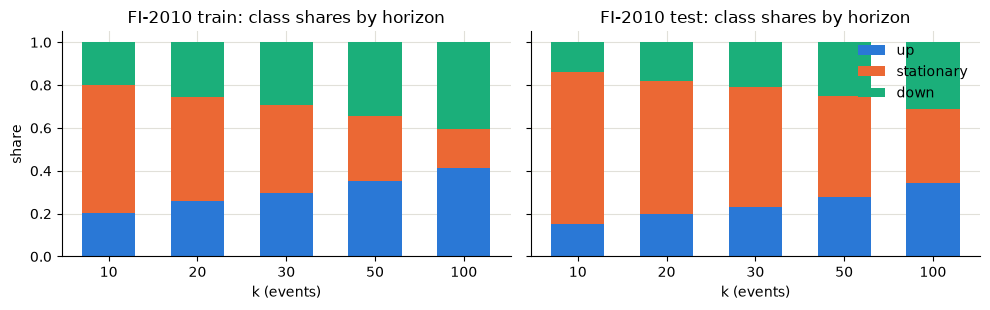

the train file is 5 stocks in a row; boundaries: [ 23336  68210 106759 161434] -> segment sizes [23336 44874 38549 54675 42366]


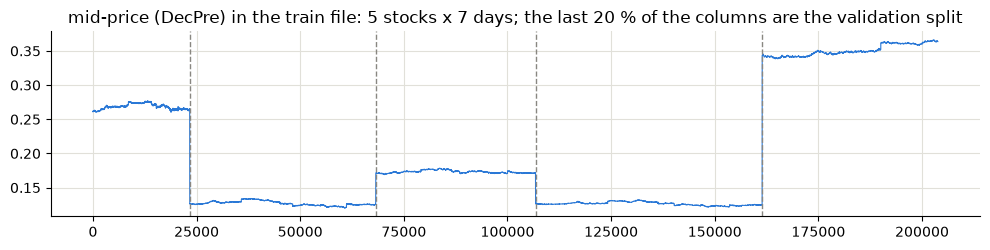

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, split in zip(axes, ('train', 'test')):
    d = shares.xs(split, level='split'); bottom = np.zeros(len(d))
    for i, cls in enumerate(['up', 'stationary', 'down']):
        ax.bar(d.index.astype(str), d[cls], bottom=bottom, color=C[i], label=cls, width=.6); bottom += d[cls].values
    ax.set_title(f'FI-2010 {split}: class shares by horizon'); ax.set_xlabel('k (events)')
axes[0].set_ylabel('share'); axes[1].legend(frameon=False, loc='upper right'); plt.tight_layout(); plt.show()

mid, bid, ask = fi2010_mid_bid_ask(train_raw); bounds = fi2010_segment_boundaries(train_raw)
print('the train file is 5 stocks in a row; boundaries:', bounds, '-> segment sizes', np.diff(np.r_[0, bounds, len(mid)]))
fig, ax = plt.subplots(figsize=(10, 2.6)); ax.plot(mid, color=C[0], lw=.8)
[ax.axvline(b, color='#898781', ls='--', lw=1) for b in bounds]
ax.set_title('mid-price (DecPre) in the train file: 5 stocks x 7 days; the last 20 % of the columns are the validation split'); plt.tight_layout(); plt.show()

The labels cannot be recomputed from the mid-price in the files (agreement 50–62 % at best), so α is varied only on crypto (Table D).

In [13]:
mid64 = mid.astype(np.float64)
for k in (10, 50, 100):
    _, y = fi2010_xy(train_raw, k)
    l = smoothed_label_signal(mid64, k // 10, 'eq3'); ok = ~np.isnan(l)
    lab_paper = signal_to_label(l[ok], 0.002)
    alpha_best = np.quantile(np.abs(l[ok]), np.mean(y[ok] == 1)); lab_best = signal_to_label(l[ok], alpha_best)
    print(f'k={k:3d}: alpha=0.002 -> agreement {np.mean(lab_paper == y[ok]):.3f} (stationary share {np.mean(lab_paper==1):.2f});'
          f'  best alpha={alpha_best:.1e} -> agreement {np.mean(lab_best == y[ok]):.3f}')

k= 10: alpha=0.002 -> agreement 0.598 (stationary share 1.00);  best alpha=0.0e+00 -> agreement 0.617
k= 50: alpha=0.002 -> agreement 0.304 (stationary share 1.00);  best alpha=0.0e+00 -> agreement 0.498
k=100: alpha=0.002 -> agreement 0.179 (stationary share 1.00);  best alpha=1.5e-05 -> agreement 0.507


## 5. Why the paper's recipe does not train

Adam with ε = 1 is close to SGD with a small step, and the network has no BatchNorm. Gradient norm per layer at initialisation:

DecPre   init=torch  first conv 6.3e-07   output layer 7.3e-02   ratio 1.2e+05


DecPre   init=keras  first conv 5.2e-04   output layer 1.1e-03   ratio 2.2e+00


z-score  init=torch  first conv 2.3e-06   output layer 7.3e-02   ratio 3.2e+04


z-score  init=keras  first conv 8.2e-04   output layer 1.8e-03   ratio 2.2e+00


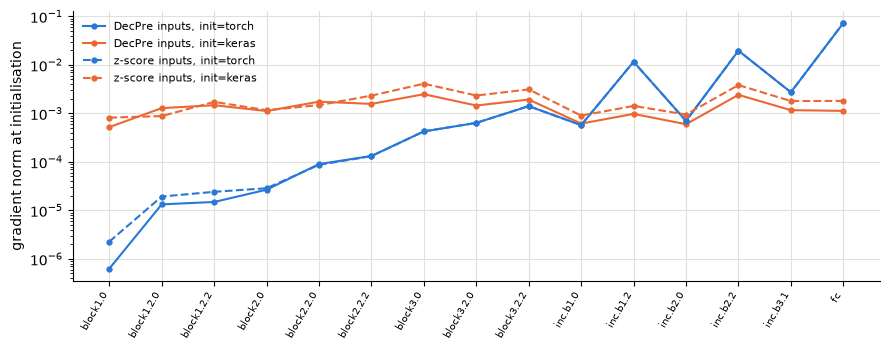

In [14]:
Xg, yg = fi2010_xy(train_raw, 10)
n = 256
mu, sd = Xg.mean(0), Xg.std(0) + 1e-8
variants = {'DecPre': Xg[:n + 99], 'z-score': ((Xg - mu) / sd).astype(np.float32)[:n + 99]}
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, (inp, Xs) in enumerate(variants.items()):
    xb, yb = make_window_data(Xs, yg[:n + 99], 100, 'cpu').batch(torch.arange(n))
    for j, init in enumerate(('torch', 'keras')):
        torch.manual_seed(0)
        m = build_model('deeplob', 'paper', init=init)
        nn.CrossEntropyLoss()(m(xb), yb).backward()
        g = [(name.replace('.weight', ''), p.grad.norm().item()) for name, p in m.named_parameters() if name.endswith('weight') and p.dim() > 1]
        ax.plot([v for _, v in g], marker='o', ms=3.5, lw=1.5, color=C[j], ls='-' if i == 0 else '--', label=f'{inp} inputs, init={init}')
        print(f'{inp:8s} init={init:5s}  first conv {g[0][1]:.1e}   output layer {g[-1][1]:.1e}   ratio {g[-1][1] / g[0][1]:.1e}')
ax.set_yscale('log'); ax.set_ylabel('gradient norm at initialisation')
ax.set_xticks(range(len(g)), [name.replace('conv.', '').replace('incep.', 'inc.') for name, _ in g], rotation=60, ha='right', fontsize=7)
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

PyTorch init: the gradient at the first convolution is 10⁴–10⁵ times smaller than at the output. Keras init: about the same in all layers.

## 6. Pipeline check on a subset

### 6.1 Authors' pipeline, k=100

Their notebook on the full data: accuracy 0.7535.

In [15]:
k_idx, T = 4, 100          # k=4 in the authors' notebook = 100 events
def authors_xy(raw, n):
    raw = raw[:, :n + T - 1]            # the full (N, 100, 40) float64 array would take 6.5 GB
    x, y = data_classification(prepare_x(raw), get_label(raw), T)
    y = y[:, k_idx] - 1
    return torch.from_numpy(x).unsqueeze(1).float(), torch.from_numpy(y).long()
xa_tr, ya_tr = authors_xy(train_raw, N_TRAIN)
xa_va, ya_va = authors_xy(val_raw, N_EVAL)
xa_te, ya_te = authors_xy(test_raw, N_EVAL * 2)
print('authors\' windows:', xa_tr.shape, xa_va.shape, xa_te.shape)

torch.manual_seed(0)
model_a = deeplob(y_len=3).to(device)
criterion = nn.CrossEntropyLoss(); optimizer = torch.optim.Adam(model_a.parameters(), lr=0.0001)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(xa_tr, ya_tr), batch_size=64, shuffle=True)
best, best_state = np.inf, None
t0 = time.time()
for ep in range(EPOCHS):
    model_a.train()
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad(); loss = criterion(model_a(xb), yb); loss.backward(); optimizer.step()
    model_a.eval()
    with torch.no_grad():
        vl = criterion(model_a(xa_va.to(device)), ya_va.to(device)).item()
    if vl < best: best, best_state = vl, {k: v.clone() for k, v in model_a.state_dict().items()}
    print(f'epoch {ep+1}: train loss {loss.item():.4f}  val loss {vl:.4f}  ({time.time()-t0:.0f}s)')
model_a.load_state_dict(best_state); model_a.eval()
with torch.no_grad():
    pred_a = torch.cat([model_a(xa_te[i:i+1024].to(device)).argmax(1).cpu() for i in range(0, len(xa_te), 1024)]).numpy()
m_authors = classification_metrics(ya_te.numpy(), pred_a)
print(f"authors' code, k=100, subset: acc {m_authors['accuracy']:.4f}  F1 weighted {m_authors['f1_weighted']:.4f}  F1 macro {m_authors['f1_macro']:.4f}")

authors' windows: torch.Size([12000, 1, 100, 40]) torch.Size([3000, 1, 100, 40]) torch.Size([6000, 1, 100, 40])


epoch 1: train loss 0.9390  val loss 1.0848  (45s)


epoch 2: train loss 0.8685  val loss 1.1297  (93s)


authors' code, k=100, subset: acc 0.4180  F1 weighted 0.4126  F1 macro 0.3671


### 6.2 Our pipeline

The `paper` config runs with `init='keras', zscore=1` (Section 5).

In [16]:
demo_kw = dict(max_train_samples=N_TRAIN, max_val_samples=N_EVAL, max_test_samples=N_EVAL * 2, epochs=EPOCHS,
               tag='demo', out_dir='results_demo', overwrite=True)
demo = []
for model_name, cfg, k in [('deeplob_authors', 'code', 100), ('deeplob', 'code', 100), ('deeplob', 'paper', 10), ('majority', 'paper', 10)]:
    recipe = dict(init='keras', zscore=1) if cfg == 'paper' else dict(init='keras') if model_name == 'deeplob' else {}
    r = run_experiment(dataset='fi2010', k=k, seed=0, model=model_name, config=cfg, **recipe, **demo_kw)
    demo.append(dict(model=model_name, config=cfg, k=k, params=r['n_params'], acc=r['test']['accuracy'],
                     f1_w=r['test']['f1_weighted'], f1_m=r['test']['f1_macro'], minutes=r.get('total_minutes', 0)))
pd.DataFrame(demo).round(4)

run fi2010_k100_deeplob_authors_code_s0_demo   hyper-parameters {'lr': 0.0001, 'adam_eps': 1e-08, 'batch_size': 64, 'epochs': 2, 'patience': 50, 'es_metric': 'loss'}


windows: train 12,000 val 3,000 test 6,000  (load 0s)


class share train up/stat/down = [0.419, 0.169, 0.412]  test = [0.488, 0.134, 0.378]


model deeplob_authors (code, init=torch): 143,907 parameters


epoch   1/2 train_loss 1.0538 val_loss 1.0924 val_acc 0.3750 val_f1m 0.2213 48s *


...

features standardised with train-split statistics (z-score)


windows: train 12,000 val 3,000 test 6,000  (load 0s)


class share train up/stat/down = [0.282, 0.447, 0.272]  test = [0.259, 0.514, 0.227]


majority baseline: acc 0.5140 f1_macro 0.2263


,model,config,k,params,acc,f1_w,f1_m,minutes
0,deeplob_authors,code,100,143907,0.3693,0.3895,0.3641,1.5966
1,deeplob,code,100,142691,0.4877,0.3197,0.2185,1.6757
2,deeplob,paper,10,60947,0.5140,0.3490,0.2263,1.5672
3,majority,paper,10,0,0.5140,0.3490,0.2263,0.0000


### 6.3 Ablation models and crypto

Crypto data are not in the repository (≈0.7 GB from Tardis.dev): set `GET_CRYPTO = True` to download.

In [17]:
for model_name in ['deeplob_noincep', 'lstm_only', 'linear_last']:
    r = run_experiment(dataset='fi2010', k=10, seed=0, model=model_name, config='paper', init='keras', zscore=1, **demo_kw)
    demo.append(dict(model=model_name, config='paper', k=10, params=r['n_params'], acc=r['test']['accuracy'],
                     f1_w=r['test']['f1_weighted'], f1_m=r['test']['f1_macro'], minutes=r.get('total_minutes', 0)))
pd.DataFrame(demo).round(4)

run fi2010_k10_deeplob_noincep_paper_s0_kinit_zs_demo   hyper-parameters {'lr': 0.01, 'adam_eps': 1.0, 'batch_size': 32, 'epochs': 2, 'patience': 20, 'es_metric': 'acc'}


features standardised with train-split statistics (z-score)


windows: train 12,000 val 3,000 test 6,000  (load 0s)


class share train up/stat/down = [0.282, 0.447, 0.272]  test = [0.259, 0.514, 0.227]


model deeplob_noincep (paper, init=keras): 30,579 parameters


...

epoch   1/2 train_loss 1.0884 val_loss 0.9257 val_acc 0.6503 val_f1m 0.2651 0s *


epoch   2/2 train_loss 1.0784 val_loss 0.9395 val_acc 0.6377 val_f1m 0.2665 0s 


TEST  acc 30.88  P/R/F1 weighted 29.86/30.88/29.61   F1 macro 24.30   (best epoch 1, 0.0 min)


done in 0.0 min -> results_demo/fi2010_k10_linear_last_paper_s0_kinit_zs_demo


,model,config,k,params,acc,f1_w,f1_m,minutes
0,deeplob_authors,code,100,143907,0.3693,0.3895,0.3641,1.5966
1,deeplob,code,100,142691,0.4877,0.3197,0.2185,1.6757
2,deeplob,paper,10,60947,0.5140,0.3490,0.2263,1.5672
3,majority,paper,10,0,0.5140,0.3490,0.2263,0.0000
4,deeplob_noincep,paper,10,30579,0.5140,0.3490,0.2263,1.1961
5,lstm_only,paper,10,27331,0.2622,0.2654,0.2394,0.1034
6,linear_last,paper,10,123,0.3088,0.2961,0.2430,0.0038


In [18]:
GET_CRYPTO = False
DAYS = {'BTCUSDT': ['2024-12-01'] + [f'2025-{m:02d}-01' for m in range(1, 13)],      # day 0 is used only for normalisation
        'ETHUSDT': ['2025-10-01', '2025-11-01', '2025-12-01']}
if GET_CRYPTO and not os.path.exists('data/crypto/BTCUSDT_stride10.npz'):
    import urllib.request
    os.makedirs('data/crypto/raw', exist_ok=True)
    for sym, dates in DAYS.items():
        for d in dates:
            path = f'data/crypto/raw/binance_book_snapshot_25_{d}_{sym}.csv.gz'
            if not os.path.exists(path):
                urllib.request.urlretrieve(f"https://datasets.tardis.dev/v1/binance/book_snapshot_25/{d.replace('-', '/')}/{sym}.csv.gz", path)
                time.sleep(4)
        build_symbol_npz('data/crypto/raw', sym, f'data/crypto/{sym}_stride10.npz')
print('crypto data:', 'found' if os.path.exists('data/crypto/BTCUSDT_stride10.npz') else 'absent (GET_CRYPTO = False)')

crypto data: found


In [19]:
npz, eth = 'data/crypto/BTCUSDT_stride10.npz', 'data/crypto/ETHUSDT_stride10.npz'
if os.path.exists(npz):
    r = run_experiment(dataset='crypto', npz=npz, k=10, seed=0, model='deeplob', config='paper', init='keras',
                       train_days='1-8', val_days='9,10', test_days='11,12',
                       transfer_npz=eth if os.path.exists(eth) else None, transfer_test_days='1,2', **demo_kw)
    print('crypto subset: acc %.4f  F1 macro %.4f  alpha %.2e' % (r['test']['accuracy'], r['test']['f1_macro'], r['alpha']))
else:
    print('no crypto data: set GET_CRYPTO = True in the cell above')

run crypto_k10_deeplob_paper_s0_kinit_demo   hyper-parameters {'lr': 0.01, 'adam_eps': 1.0, 'batch_size': 32, 'epochs': 2, 'patience': 20, 'es_metric': 'acc'}


  train: days ['2025-01-01', '2025-02-01', '2025-03-01', '2025-04-01', '2025-05-01', '2025-06-01', '2025-07-01', '2025-08-01'] n=583,421 class share up/stat/down = [0.335, 0.333, 0.332]


  val: days ['2025-09-01', '2025-10-01'] n=157,848 class share up/stat/down = [0.35, 0.316, 0.333]


  test: days ['2025-11-01', '2025-12-01'] n=154,442 class share up/stat/down = [0.317, 0.361, 0.322]


  alpha = 3.331e-05 (eq4, k=10)


...

  test: days ['2025-11-01', '2025-12-01'] n=144,166 class share up/stat/down = [0.391, 0.211, 0.398]


  alpha = 3.331e-05 (eq4, k=10)


TRANSFER (ETHUSDT_stride10.npz) acc 21.09 F1 macro 11.61 F1 weighted 7.35


done in 3.6 min -> results_demo/crypto_k10_deeplob_paper_s0_kinit_demo


crypto subset: acc 0.5447  F1 macro 0.2351  alpha 3.33e-05


## 7. Full runs

152 runs, test set, %, mean ± std over seeds.

In [20]:
Z = zipfile.ZipFile('results/full_runs.zip')
runs = {n.split('/')[1]: json.load(Z.open(n)) for n in Z.namelist() if n.endswith('result.json')}

def flat(r):
    a, t = r['args'], r['test']
    d = dict(run=r['run'], dataset=a['dataset'], k=a['k'], model=a['model'], config=a['config'], init=a.get('init', 'torch'),
             inputs=(a.get('norm', 'DecPre') if a['dataset'] == 'fi2010' else '-') + {0: '', 1: '+zs', 2: '+zs/stock'}[int(a.get('zscore') or 0)],
             seed=a['seed'], tag=a.get('tag', ''), holdout=a.get('holdout_stock'), params=r.get('n_params'),
             acc=100 * t['accuracy'], p_w=100 * t['precision_weighted'], r_w=100 * t['recall_weighted'], f1_w=100 * t['f1_weighted'],
             f1_m=100 * t['f1_macro'], best_epoch=r.get('best_epoch'), minutes=r.get('total_minutes'), alpha=r.get('alpha'),
             top_class=100 * max(t['class_share_true']))
    if 'transfer' in r:
        d.update(eth_acc=100 * r['transfer']['accuracy'], eth_f1_m=100 * r['transfer']['f1_macro'])
    return d

df = pd.DataFrame([flat(r) for r in runs.values()])
fi = df[(df.dataset == 'fi2010') & (df.tag == '') & df.holdout.isna()]          # Setup 2, all 5 stocks
ms = lambda x: f'{x.mean():.2f} ± {x.std(ddof=1):.2f}' if len(x) > 1 else f'{x.mean():.2f}'
def table(d, by, cols):
    return d.groupby(by).agg(seeds=('seed', 'count'), **{c: (c, ms) for c in cols})
print(len(df), 'runs,', round(df.minutes.sum() / 60), 'GPU-hours')

152 runs, 116 GPU-hours


### Table A. Table II of the paper

`Zscore`: z-score files of the dataset (main recipe); `DecPre+zs`: z-score from the train split; `DecPre / torch`: the paper as written; `code`: authors' settings; `deeplob_authors`: their class.

In [21]:
table(fi[fi.model.isin(['deeplob', 'deeplob_authors'])], ['model', 'config', 'inputs', 'init', 'k'], ['acc', 'p_w', 'r_w', 'f1_w', 'f1_m', 'best_epoch'])

seeds           acc  \
model           config inputs          init  k                          
deeplob         code   DecPre          keras 10       3  83.01 ± 0.03   
                                             20       3  74.38 ± 0.15   
                                             50       3  76.85 ± 0.33   
                                             100      3  75.15 ± 1.35   
                                       torch 100      1         60.65   
                paper  DecPre          torch 10       5  70.69 ± 0.00   
                                             20       5  62.08 ± 0.00   
                                             50       5  27.53 ± 0.00   
                       DecPre+zs       keras 10       5  83.52 ± 0.20   
                                             20       5  74.94 ± 0.12   
                                             50       5  78.17 ± 0.06   
                       DecPre+zs/stock keras 10       3  83.59 ± 0.13   
                       Zscore          keras 10       5  83.51 ± 0.23   
                                             20       5  74.93 ± 0.16   
                                             50       5  78.21 ± 0.59   
deeplob_authors code   DecPre          torch 100      3  74.15 ± 1.18   

                                                           p_w           r_w  \
model           config inputs          init  k                                 
deeplob         code   DecPre          keras 10   82.16 ± 0.05  83.01 ± 0.03   
                                             20   73.25 ± 0.23  74.38 ± 0.15   
                                             50   76.84 ± 0.29  76.85 ± 0.33   
                                             100  76.19 ± 0.92  75.15 ± 1.35   
                                       torch 100         62.39         60.65   
                paper  DecPre          torch 10   49.97 ± 0.00  70.69 ± 0.00   
                                             20   38.53 ± 0.00  62.08 ± 0.00   
                                             50    7.58 ± 0.00  27.53 ± 0.00   
                       DecPre+zs       keras 10   82.82 ± 0.25  83.52 ± 0.20   
                                             20   73.85 ± 0.22  74.94 ± 0.12   
                                             50   78.07 ± 0.09  78.17 ± 0.06   
                       DecPre+zs/stock keras 10   82.91 ± 0.26  83.59 ± 0.13   
                       Zscore          keras 10   82.76 ± 0.31  83.51 ± 0.23   
                                             20   73.91 ± 0.27  74.93 ± 0.16   
                                             50   78.18 ± 0.52  78.21 ± 0.59   
deeplob_authors code   DecPre          torch 100  74.62 ± 1.02  74.15 ± 1.18   

                                                          f1_w          f1_m  \
model           config inputs          init  k                                 
deeplob         code   DecPre          keras 10   81.93 ± 0.04  71.80 ± 0.13   
                                             20   72.45 ± 0.16  63.83 ± 0.27   
                                             50   76.82 ± 0.34  75.22 ± 0.37   
                                             100  75.24 ± 1.36  75.18 ± 1.35   
                                       torch 100         60.74         60.60   
                paper  DecPre          torch 10   58.55 ± 0.00  27.61 ± 0.00   
                                             20   47.55 ± 0.00  25.53 ± 0.00   
                                             50   11.89 ± 0.00  14.39 ± 0.00   
                       DecPre+zs       keras 10   82.33 ± 0.23  72.25 ± 0.41   
                                             20   73.16 ± 0.16  64.77 ± 0.37   
                                             50   78.07 ± 0.08  76.40 ± 0.16   
                       DecPre+zs/stock keras 10   82.42 ± 0.09  72.47 ± 0.20   
                       Zscore          keras 10   82.45 ± 0.24  72.59 ± 0.45   
                                             20   73.01 ± 0.20  64.53 ± 0.33   
              

,paper acc,ours acc,paper F1 (w),ours F1 (w),ours F1 (macro),LOBCAST F1 (macro),largest test class
k,,,,,,,
10,84.47,83.51 ± 0.23,83.40,82.45 ± 0.24,72.59 ± 0.45,71.1,70.69
20,74.85,74.93 ± 0.16,72.82,73.01 ± 0.20,64.53 ± 0.33,62.4,62.08
50,80.51,78.21 ± 0.59,80.35,78.14 ± 0.55,76.48 ± 0.58,75.4,47.31


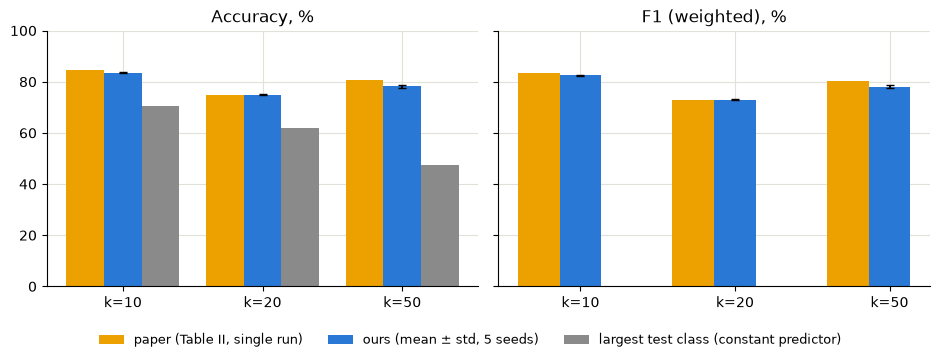

In [22]:
PAPER = {10: (84.47, 83.40), 20: (74.85, 72.82), 50: (80.51, 80.35)}       # Table II: accuracy, F1 (weighted)
LOBCAST = {10: 71.1, 20: 62.4, 50: 75.4}                                    # Prata et al. 2023, macro-F1
ours = fi[(fi.model == 'deeplob') & (fi.config == 'paper') & (fi.inputs == 'Zscore') & (fi.init == 'keras')]
display(pd.DataFrame([{'k': k, 'paper acc': PAPER[k][0], 'ours acc': ms(g.acc), 'paper F1 (w)': PAPER[k][1], 'ours F1 (w)': ms(g.f1_w),
                       'ours F1 (macro)': ms(g.f1_m), 'LOBCAST F1 (macro)': LOBCAST[k], 'largest test class': round(g.top_class.iloc[0], 2)}
                      for k, g in ours.groupby('k')]).set_index('k'))

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=True)
x = np.arange(3); wd = 0.27
for ax, col, j, title in ((axes[0], 'acc', 0, 'Accuracy, %'), (axes[1], 'f1_w', 1, 'F1 (weighted), %')):
    ax.bar(x - wd, [PAPER[k][j] for k in PAPER], wd, color=C[3], label='paper (Table II, single run)')
    ax.bar(x, [ours[ours.k == k][col].mean() for k in PAPER], wd, yerr=[ours[ours.k == k][col].std(ddof=1) for k in PAPER], capsize=3, color=C[0], label='ours (mean ± std, 5 seeds)')
    if col == 'acc':
        ax.bar(x + wd, [ours[ours.k == k].top_class.iloc[0] for k in PAPER], wd, color=C[4], label='largest test class (constant predictor)')
    ax.set_xticks(x, [f'k={k}' for k in PAPER]); ax.set_title(title); ax.set_ylim(0, 100)
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, loc='lower center', ncol=3, fontsize=9)
fig.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

1–2 pp below the paper at k=10 and k=50 (seed std 0.2–0.6 pp). The paper reports weighted F1, LOBCAST macro-F1.

Training curves, k=10, seed 0:

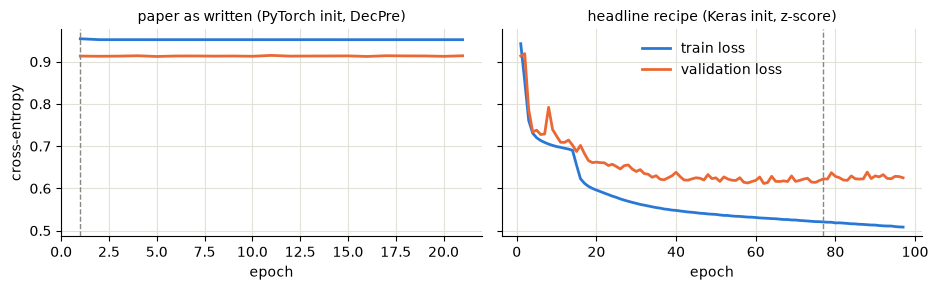

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3), sharey=True)
for ax, (run, title) in zip(axes, (('fi2010_k10_deeplob_paper_s0', 'paper as written (PyTorch init, DecPre)'),
                                   ('fi2010_k10_deeplob_paper_s0_zscore_kinit', 'headline recipe (Keras init, z-score)'))):
    h = pd.DataFrame(runs[run]['history'])
    ax.plot(h.epoch + 1, h.train_loss, color=C[0], lw=2, label='train loss'); ax.plot(h.epoch + 1, h.val_loss, color=C[1], lw=2, label='validation loss')
    ax.axvline(runs[run]['best_epoch'], color='#898781', ls='--', lw=1); ax.set_title(title, fontsize=10); ax.set_xlabel('epoch')
axes[0].set_ylabel('cross-entropy'); axes[1].legend(frameon=False); plt.tight_layout(); plt.show()

### Table B. Ablation (k=10)

,params,seeds,acc,f1_w,f1_m
model,,,,,
deeplob,60947,5,83.51 ± 0.23,82.45 ± 0.24,72.59 ± 0.45
deeplob_noincep,30579,3,83.46 ± 0.11,82.44 ± 0.19,72.57 ± 0.32
deeplob_nolstm,633939,3,82.39 ± 0.19,81.22 ± 0.32,70.22 ± 0.64
lstm_only,27331,3,78.16 ± 0.27,76.45 ± 0.09,63.32 ± 0.05
linear_window,12003,3,71.59 ± 1.16,65.65 ± 0.52,43.76 ± 0.20
linear_last,123,3,70.68 ± 0.01,58.57 ± 0.01,27.66 ± 0.01


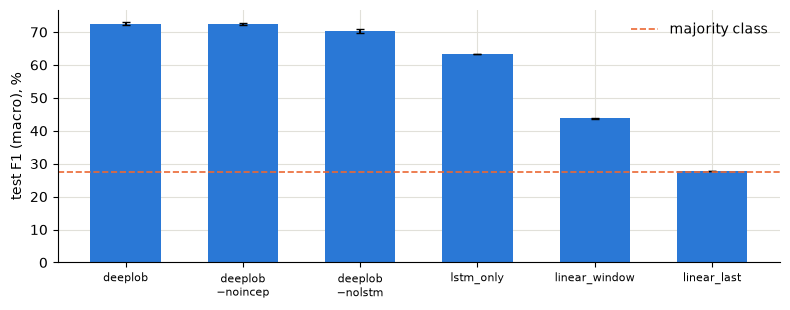

In [24]:
order = ['deeplob', 'deeplob_noincep', 'deeplob_nolstm', 'lstm_only', 'linear_window', 'linear_last']
abl = fi[(fi.k == 10) & (fi.config == 'paper') & (fi.inputs == 'Zscore') & (fi.init == 'keras')]
B = table(abl, ['model', 'params'], ['acc', 'f1_w', 'f1_m']).reset_index().set_index('model').loc[order]
display(B)
m = [abl[abl.model == a].f1_m.mean() for a in order]; s = [abl[abl.model == a].f1_m.std(ddof=1) for a in order]
fig, ax = plt.subplots(figsize=(8, 3.2)); ax.bar(range(len(order)), m, yerr=s, capsize=3, color=C[0], width=.6)
ax.axhline(fi[(fi.k == 10) & (fi.model == 'majority')].f1_m.mean(), color=C[1], ls='--', lw=1.2, label='majority class')
ax.set_xticks(range(len(order)), [o.replace('deeplob_', 'deeplob\n−') for o in order], fontsize=8); ax.set_ylabel('test F1 (macro), %')
ax.legend(frameon=False); plt.tight_layout(); plt.show()

Without Inception the result is the same; without the convolutions −9 pp.

### Table C. Binance BTCUSDT, transfer to ETHUSDT

Train: first days of Jan–Aug 2025, val: Sep–Oct, test: Nov–Dec. `eth_*`: the same model on ETHUSDT without retraining.

seeds           acc          f1_w          f1_m       eth_acc  \
model       k                                                                   
deeplob     10      3  64.40 ± 1.86  64.15 ± 2.24  64.04 ± 2.32  47.53 ± 7.19   
            20      3  60.31 ± 0.71  59.93 ± 0.81  59.97 ± 0.82  44.86 ± 5.74   
            50      3  52.31 ± 4.47  50.83 ± 4.67  51.16 ± 4.50  42.41 ± 9.43   
linear_last 10      3  51.30 ± 1.01  46.97 ± 1.09  47.77 ± 1.18  52.12 ± 2.04   
majority    10      1         31.69         15.25         16.04             –   
            20      1         31.27         14.89         15.88             –   
            50      1         30.90         14.59         15.74             –   

                     eth_f1_m  
model       k                  
deeplob     10   46.60 ± 7.75  
            20   42.36 ± 7.52  
            50  37.74 ± 10.61  
linear_last 10   38.25 ± 2.57  
majority    10              –  
            20              –  
            50              –

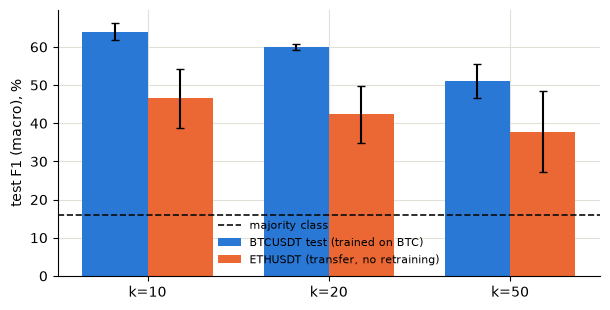

In [25]:
cr = df[(df.dataset == 'crypto') & (df.tag == '')]
display(table(cr, ['model', 'k'], ['acc', 'f1_w', 'f1_m']).join(table(cr[cr.model != 'majority'], ['model', 'k'], ['eth_acc', 'eth_f1_m']).drop(columns='seeds')).fillna('–'))
d = cr[cr.model == 'deeplob']; ks = sorted(d.k.unique()); x = np.arange(len(ks)); wd = 0.36
fig, ax = plt.subplots(figsize=(6.2, 3.2))
for i, (col, lab) in enumerate((('f1_m', 'BTCUSDT test (trained on BTC)'), ('eth_f1_m', 'ETHUSDT (transfer, no retraining)'))):
    ax.bar(x + (i - .5) * wd, [d[d.k == k][col].mean() for k in ks], wd, yerr=[d[d.k == k][col].std(ddof=1) for k in ks], capsize=3, color=C[i], label=lab)
ax.axhline(cr[cr.model == 'majority'].f1_m.mean(), color='#0b0b0b', ls='--', lw=1.2, label='majority class')
ax.set_xticks(x, [f'k={k}' for k in ks]); ax.set_ylabel('test F1 (macro), %'); ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

### Table D. Embargo, label formula, α

`embargo`: last k train labels dropped; `eq3`: labels by eq. 3; `stat20` / `stat50`: stationary share 20 % / 50 %.

In [26]:
D = df[(df.tag != '') & df.holdout.isna()]
display(table(D, ['dataset', 'k', 'tag'], ['acc', 'f1_m', 'top_class']))
base = cr[(cr.model == 'deeplob') & (cr.k == 10)]
print('base rows:  FI-2010 k=10 macro-F1', ms(ours[ours.k == 10].f1_m), '|  BTC k=10 acc', ms(base.acc), 'macro-F1', ms(base.f1_m), 'largest class', round(base.top_class.iloc[0], 1))

seeds           acc          f1_m     top_class
dataset k  tag                                                     
crypto  10 eq3          3  55.91 ± 0.93  55.90 ± 0.96  34.80 ± 0.00
           stat20       3  67.68 ± 0.60  67.03 ± 0.90  38.03 ± 0.00
           stat50       3  63.56 ± 1.24  60.30 ± 2.43  49.95 ± 0.00
fi2010  10 embargo      3  83.63 ± 0.05  72.63 ± 0.09  70.79 ± 0.00

base rows:  FI-2010 k=10 macro-F1 72.59 ± 0.45 |  BTC k=10 acc 64.40 ± 1.86 macro-F1 64.04 ± 2.32 largest class 36.1


### Table E. Leave-one-stock-out

Train on 4 stocks, test on the fifth. `Zscore`: pooled statistics; `DecPre+zs/stock`: per-stock statistics.

In [27]:
all5 = json.load(Z.open('derived/all5_per_stock.json'))      # per-stock metrics of the models trained on all 5 stocks
lo = df[(df.dataset == 'fi2010') & df.holdout.notna() & (df.model == 'deeplob')]
rows = []
for (inp, k, h), g in lo.groupby(['inputs', 'k', 'holdout']):
    a5 = np.array(all5[f'{k}|{inp}'][str(int(h))])          # accuracy, macro-F1, test windows, largest class
    rows.append({'inputs': inp, 'k': k, 'stock': int(h), 'test windows': int(a5[0, 2]), 'all-5 F1 (macro)': ms(pd.Series(a5[:, 1])),
                 'LOSO F1 (macro)': ms(g.f1_m), 'seeds': len(g), 'drop, pp': round(a5[:, 1].mean() - g.f1_m.mean(), 2)})
E = pd.DataFrame(rows).set_index(['inputs', 'k', 'stock'])
display(E)
print(E.groupby(['inputs', 'k'])['drop, pp'].mean().round(2).rename('mean drop, pp').to_string())

test windows all-5 F1 (macro) LOSO F1 (macro)  \
inputs          k  stock                                                  
DecPre+zs/stock 10 0              6309     57.41 ± 0.35    55.02 ± 0.42   
                   1             23061     77.12 ± 0.36    76.16 ± 0.01   
                   2             24349     77.47 ± 0.73    76.10 ± 0.17   
                   3             31930     75.11 ± 0.36    75.34 ± 0.34   
                   4             53839     68.14 ± 0.32    65.12 ± 0.34   
Zscore          10 0              6309     57.81 ± 0.73    53.14 ± 1.22   
                   1             23061     77.24 ± 0.37    76.48 ± 0.32   
                   2             24349     77.53 ± 0.73    76.51 ± 0.30   
                   3             31930     75.04 ± 0.41    75.20 ± 0.05   
                   4             53839     68.18 ± 0.42   34.99 ± 11.70   
                50 0              6309     54.37 ± 1.05    52.79 ± 0.72   
                   1             23061     81.31 ± 1.07    79.77 ± 0.45   
                   2             24349     83.63 ± 0.80    82.18 ± 0.32   
                   3             31930     81.04 ± 0.44    80.79 ± 0.31   
                   4             53839     68.96 ± 0.68    26.51 ± 3.37   

                          seeds  drop, pp  
inputs          k  stock                   
DecPre+zs/stock 10 0          3      2.39  
                   1          2      0.96  
                   2          2      1.37  
                   3          2     -0.24  
                   4          3      3.03  
Zscore          10 0          3      4.67  
                   1          3      0.76  
                   2          3      1.02  
                   3          3     -0.16  
                   4          3     33.19  
                50 0          3      1.58  
                   1          3      1.53  
                   2          3      1.45  
                   3          3      0.25  
                   4          3     42.44

inputs           k 
DecPre+zs/stock  10    1.50
Zscore           10    7.90
                 50    9.45


With the pooled z-score the price level identifies the stock, and stock 4 collapses to one class.

### Trading simulation (Sec. V.D)

`mid`: mid-price, no fees (as in the paper); `spread`: buy at the ask, sell at the bid. Second cell: the same function on the models of Section 6.

In [28]:
tr = pd.read_csv(Z.open('derived/trading_simulation.csv'))
tr['data'] = tr.run.str.split('_').str[0]; tr['k'] = tr.run.str.extract(r'_k(\d+)_')[0].astype(int)
tr.groupby(['data', 'k', 'cost'])[['trades', 'mean_pnl_bps', 'tstat_segments', 'avg_spread_bps']].mean().round(2)

trades  mean_pnl_bps  tstat_segments  \
data   k  cost                                                        
crypto 10 mid                 7718.33          0.33           10.06   
          spread              7718.33          0.33            9.79   
          spread + 2 bps fee  7718.33         -3.67           -1.47   
       20 mid                 5868.00          0.42           10.25   
          spread              5868.00          0.42           10.59   
          spread + 2 bps fee  5868.00         -3.58           -1.54   
       50 mid                 3732.33          0.46           10.42   
          spread              3732.33          0.46           10.53   
          spread + 2 bps fee  3732.33         -3.54           -1.87   
fi2010 10 mid                 7768.20          0.43            4.42   
          spread              7768.20        -15.88           -6.97   
       20 mid                 8145.80          0.40            4.92   
          spread              8145.80        -15.87           -6.78   
       50 mid                 8802.60          0.51            6.45   
          spread              8802.60        -15.51           -6.52   

                              avg_spread_bps  
data   k  cost                                
crypto 10 mid                           0.00  
          spread                        0.00  
          spread + 2 bps fee            0.00  
       20 mid                           0.00  
          spread                        0.00  
          spread + 2 bps fee            0.00  
       50 mid                           0.00  
          spread                        0.00  
          spread + 2 bps fee            0.00  
fi2010 10 mid                          15.59  
          spread                       15.59  
       20 mid                          15.59  
          spread                       15.59  
       50 mid                          15.59  
          spread                       15.59

In [29]:
rows = []
for f in sorted(glob.glob('results_demo/fi2010_k*_deeplob_*/predictions.npz')):
    z = np.load(f); pred, t = z['logits'].argmax(1), z['t_index']
    seg = np.searchsorted(t, z['test_segment_starts'])
    for cost in ('mid', 'spread'):
        r = simulate(pred, z['test_mid'][t], z['test_bid'][t], z['test_ask'][t], seg, cost=cost)
        rows.append(dict(run=os.path.basename(os.path.dirname(f)), cost=cost, trades=r['n_trades'], mean_pnl_bps=round(r['mean_pnl_bps'], 3), win_rate=round(r['win_rate'], 3)))
pd.DataFrame(rows)

,run,cost,trades,mean_pnl_bps,win_rate
0,fi2010_k100_deeplob_authors_code_s0_demo,mid,209,-0.015,0.421
1,fi2010_k100_deeplob_authors_code_s0_demo,spread,209,-20.682,0.091
2,fi2010_k100_deeplob_code_s0_kinit_demo,mid,2,170.316,1.000
3,fi2010_k100_deeplob_code_s0_kinit_demo,spread,2,150.802,1.000
4,fi2010_k10_deeplob_noincep_paper_s0_kinit_zs_demo,mid,0,0.000,0.000
5,fi2010_k10_deeplob_noincep_paper_s0_kinit_zs_demo,spread,0,0.000,0.000
6,fi2010_k10_deeplob_paper_s0_kinit_zs_demo,mid,0,0.000,0.000
7,fi2010_k10_deeplob_paper_s0_kinit_zs_demo,spread,0,0.000,0.000


## 8. Conclusions

- Table II (accuracy / weighted F1, ours vs paper): k=10: 83.51 ± 0.23 / 82.45 ± 0.24 vs 84.47 / 83.40; k=20: 74.93 ± 0.16 / 73.01 ± 0.20 vs 74.85 / 72.82; k=50: 78.21 ± 0.59 / 78.14 ± 0.55 vs 80.51 / 80.35.
- As written (Adam ε = 1, PyTorch init) all 15 runs stay at the class prior (k=10: 70.69 ± 0.00); with Keras init and z-scored inputs the network trains.
- k=10: macro-F1 72.59 ± 0.45, weighted F1 82.45 ± 0.24. LOBCAST reports 71.1 / 62.4 / 75.4 (macro-F1), ours 72.6 / 64.5 / 76.5.
- Ablation, macro-F1: full 72.59 ± 0.45, no Inception 72.57 ± 0.32, no LSTM 70.22 ± 0.64, LSTM only 63.32 ± 0.05, linear 43.76 ± 0.20 / 27.66 ± 0.01.
- BTCUSDT macro-F1: 64.04 ± 2.32 / 59.97 ± 0.82 / 51.16 ± 4.50 (k = 10 / 20 / 50); ETHUSDT without retraining: 46.60 ± 7.75.
- Leave-one-stock-out: −7.90 pp with the pooled z-score, −1.50 pp with per-stock z-score.
- Trading: +0.45 bps per trade at the mid-price, -15.8 bps with the spread.
- Embargo: 72.63 ± 0.09 vs 72.59 ± 0.45; eq. 3 labels on crypto: −8 pp.